## Task 1: Setting the Baseline

In ML, it is essential to establish a baseline model for comparison with any developments.

### Task 1.1 Data Preparation and Validation Pipeline

- First, explore the training data for any anomalies and visualize some trajectories. Each trajectory consists of 258 lines, one per data point. Note that after a collision, all lines of that trajectory will be zero up to the 258th data point for that trajectory.

Necessary imports

In [3]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType

Load dataset from CSV file and analyze it in terms of missing values and dataset summary

In [4]:
df = pd.read_csv('../mlNOVA/X_train.csv')

# print(df.isnull().sum())
# print(df.describe())
df.head()

,t,x_1,y_1,v_x_1,v_y_1,x_2,y_2,v_x_2,v_y_2,x_3,y_3,v_x_3,v_y_3,Id
0,0.000000,1.000000,0.000000,0.000000,0.000000,-0.266467,0.859196,0.000000,0.000000,-0.733533,-0.859196,0.000000,0.000000,0
1,0.039062,0.999548,0.000092,-0.023159,0.004731,-0.266261,0.858781,0.010574,-0.021257,-0.733287,-0.858874,0.012584,0.016526,1
2,0.078125,0.998190,0.000370,-0.046362,0.009474,-0.265641,0.857535,0.021172,-0.042552,-0.732549,-0.857905,0.025189,0.033078,2
3,0.117188,0.995925,0.000833,-0.069654,0.014239,-0.264606,0.855456,0.031817,-0.063924,-0.731318,-0.856289,0.037837,0.049685,3
4,0.156250,0.992747,0.001483,-0.093080,0.019040,-0.263154,0.852540,0.042533,-0.085412,-0.729592,-0.854022,0.050548,0.066372,4


Dataframe should have the data grouped by scenarios

In [5]:
# got this code from https://stackoverflow.com/questions/17315737/split-a-large-pandas-dataframe or https://www.statology.org/pandas-chunk-dataframe/
SUBFRAME_SIZE = 257

def fixed_size_subframes(data, n):
    return [data[i : i + n].copy() for i in range(0, data.shape[0], n)]

subframes = fixed_size_subframes(df, SUBFRAME_SIZE)

Visualize trajectories

2


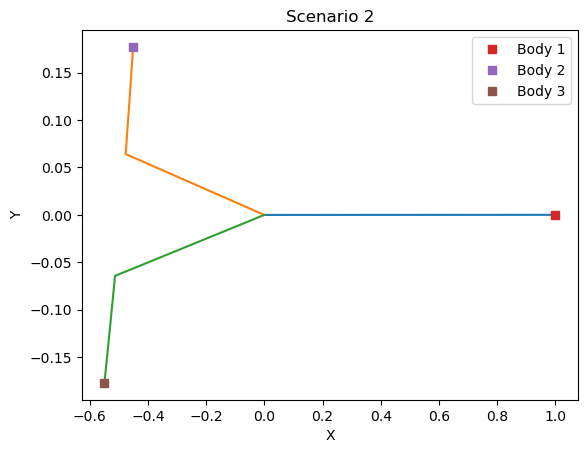

5


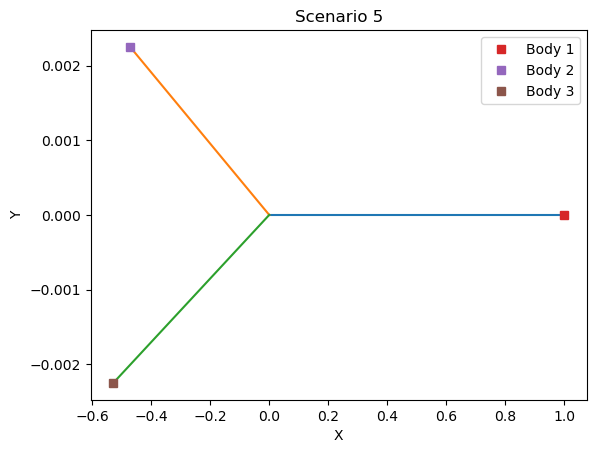

284


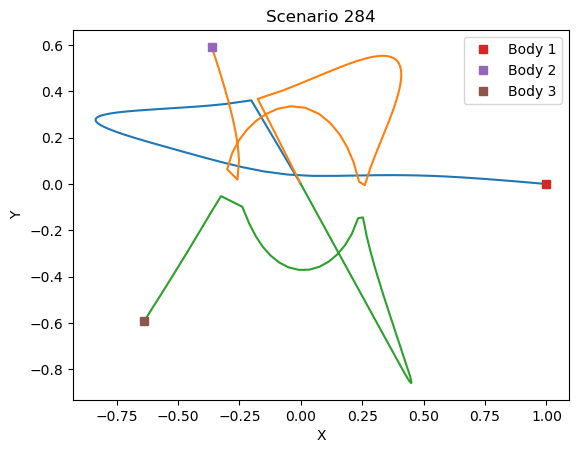

315


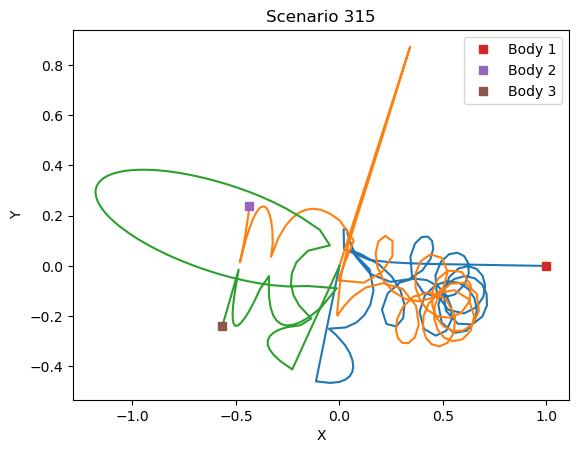

317


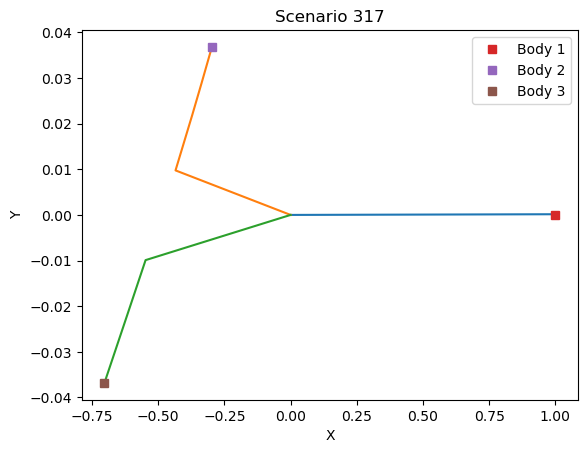

338


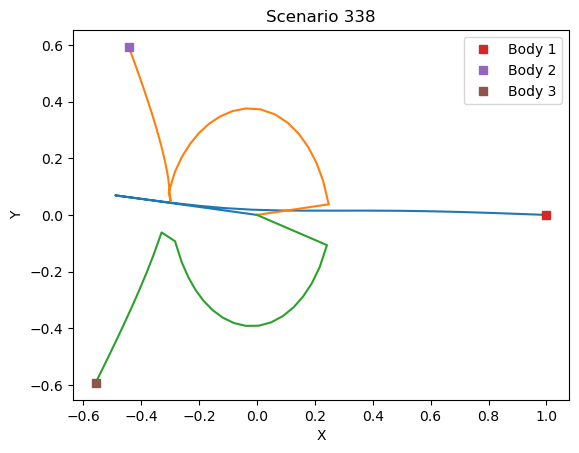

4643


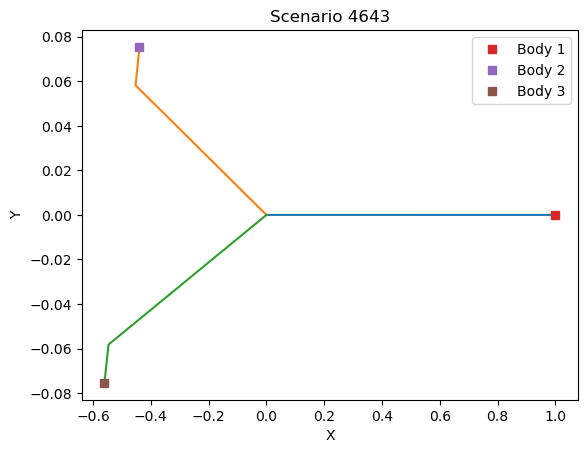

In [6]:
# k = np.random.randint(len(subframes))

ks = [2, 5, 284, 315, 317, 338, 4643] # some scenarios with collisions
#ks = range(10)

for k in ks:
    subframe = subframes[k]
    first_row = subframe.iloc[0]
    
    print(k)
    plt.figure()

    plt.plot(subframe.x_1, subframe.y_1)
    plt.plot(subframe.x_2, subframe.y_2)
    plt.plot(subframe.x_3, subframe.y_3)

    plt.plot(first_row.x_1, first_row.y_1, 's', label='Body 1')
    plt.plot(first_row.x_2, first_row.y_2, 's', label='Body 2')
    plt.plot(first_row.x_3, first_row.y_3, 's', label='Body 3')
    
    plt.legend()
    plt.title(f'Scenario {k}')
    plt.xlabel('X')
    plt.ylabel('Y')
    
    plt.show()

In [7]:
def remove_useless_rows(subframes):
    cleaned_subframes = []
    
    for df in subframes:
        # Identify rows where all values except for 'Id' are 0
        mask = (df.drop(columns=['Id']) != 0).any(axis=1)
        
        # Filter out the "useless" rows
        cleaned_df = df[mask]
        
        # Append the cleaned dataframe to the list
        if not cleaned_df.empty:
            cleaned_subframes.append(cleaned_df)
    
    return cleaned_subframes

# Assuming 'subframes' is your list of dataframes, each representing a simulation
subframes = remove_useless_rows(subframes)

In [23]:
def check_empty_dataframes(subframes):
    empty_dataframes = []
    
    for i, df in enumerate(subframes):
        if df.empty:
            empty_dataframes.append(i)
            print(f"DataFrame at index {i} is empty.")
    
    if not empty_dataframes:
        print("No empty dataframes found.")
    else:
        print(f"Empty dataframes found at indices: {empty_dataframes}")

# Call the function with your list of dataframes
check_empty_dataframes(subframes)


DataFrame at index 1050 is empty.
DataFrame at index 4058 is empty.
Empty dataframes found at indices: [1050, 4058]


Delete scenarios who would induce a collision, as these are anomalies

In [8]:
#subframes = [sf for sf in subframes if sf.iloc[256]['t'] != 0]
len(subframes)

4998

Create features and target matrices from the grouped data

In [26]:
def create_features_and_targets(subframes):
    X_list = []
    y_list = []
    
    for df in subframes:
        initial_conditions = df.iloc[0][['x_1', 'y_1', 'v_x_1', 'v_y_1', 'x_2', 'y_2', 'v_x_2', 'v_y_2', 'x_3', 'y_3', 'v_x_3', 'v_y_3']].values
        
        for i, row in df.iterrows():
            features = [row['t']] + initial_conditions.tolist()
            X_list.append(features)
            
            targets = row[['x_1', 'y_1', 'v_x_1', 'v_y_1', 'x_2', 'y_2', 'v_x_2', 'v_y_2', 'x_3', 'y_3', 'v_x_3', 'v_y_3']].values
            y_list.append(targets)

    X = pd.DataFrame(X_list, columns=['t', 'x0_1', 'y0_1','v_x0_1', 'v_y0_1', 'x0_2', 'y0_2','v_x0_2', 'v_y0_2', 'x0_3', 'y0_3', 'v_x0_3', 'v_y0_3'])
    y = pd.DataFrame(y_list, columns=['x_1', 'y_1', 'v_x_1', 'v_y_1', 'x_2', 'y_2', 'v_x_2', 'v_y_2', 'x_3', 'y_3', 'v_x_3', 'v_y_3'])
    
    return X, y


X, y = create_features_and_targets(subframes)

Features and target matrices should have information grouped by scenario

In [27]:
X_chunks = fixed_size_subframes(X, SUBFRAME_SIZE)
y_chunks = fixed_size_subframes(y, SUBFRAME_SIZE)

print(X_chunks[0].head())
print(y_chunks[0].head())

          t  x0_1  y0_1  v_x0_1  v_y0_1      x0_2      y0_2  v_x0_2  v_y0_2  \
0  0.000000   1.0   0.0     0.0     0.0 -0.266467  0.859196     0.0     0.0   
1  0.039062   1.0   0.0     0.0     0.0 -0.266467  0.859196     0.0     0.0   
2  0.078125   1.0   0.0     0.0     0.0 -0.266467  0.859196     0.0     0.0   
3  0.117188   1.0   0.0     0.0     0.0 -0.266467  0.859196     0.0     0.0   
4  0.156250   1.0   0.0     0.0     0.0 -0.266467  0.859196     0.0     0.0   

       x0_3      y0_3  v_x0_3  v_y0_3  
0 -0.733533 -0.859196     0.0     0.0  
1 -0.733533 -0.859196     0.0     0.0  
2 -0.733533 -0.859196     0.0     0.0  
3 -0.733533 -0.859196     0.0     0.0  
4 -0.733533 -0.859196     0.0     0.0  
        x_1       y_1     v_x_1     v_y_1       x_2       y_2     v_x_2  \
0  1.000000  0.000000  0.000000  0.000000 -0.266467  0.859196  0.000000   
1  0.999548  0.000092 -0.023159  0.004731 -0.266261  0.858781  0.010574   
2  0.998190  0.000370 -0.046362  0.009474 -0.265641  0.85753

Split dataset into training (80%), validation (10%) and test (10%) sets.

In [11]:
def create_features_and_targets(cleaned_subframes):
    X_chunks = []
    y_chunks = []
    
    for df in cleaned_subframes:
        if df.empty:
            continue
        
        initial_conditions = df.iloc[0][['x_1', 'y_1', 'v_x_1', 'v_y_1', 'x_2', 'y_2', 'v_x_2', 'v_y_2', 'x_3', 'y_3', 'v_x_3', 'v_y_3']].values
        
        # Create the features and targets for this simulation (scenario)
        X_list = [[row['t']] + initial_conditions.tolist() for _, row in df.iterrows()]
        y_list = [row[['x_1', 'y_1', 'v_x_1', 'v_y_1', 'x_2', 'y_2', 'v_x_2', 'v_y_2', 'x_3', 'y_3', 'v_x_3', 'v_y_3']].values for _, row in df.iterrows()]
        
        # Convert the lists to DataFrames
        X_chunk = pd.DataFrame(X_list, columns=['t', 'x0_1', 'y0_1', 'v_x0_1', 'v_y0_1', 'x0_2', 'y0_2', 'v_x0_2', 'v_y0_2', 'x0_3', 'y0_3', 'v_x0_3', 'v_y0_3'])
        y_chunk = pd.DataFrame(y_list, columns=['x_1', 'y_1', 'v_x_1', 'v_y_1', 'x_2', 'y_2', 'v_x_2', 'v_y_2', 'x_3', 'y_3', 'v_x_3', 'v_y_3'])
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk)
        y_chunks.append(y_chunk)
    
    return X_chunks, y_chunks

# Example of using the function on the cleaned dataset
X_chunks, y_chunks = create_features_and_targets(subframes)

In [12]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=1)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=1)

print(X_train[0].head())
print(y_train[0].head())

          t  x0_1  y0_1  v_x0_1  v_y0_1      x0_2      y0_2  v_x0_2  v_y0_2  \
0  0.000000   1.0   0.0     0.0     0.0 -0.032595  0.511599     0.0     0.0   
1  0.039062   1.0   0.0     0.0     0.0 -0.032595  0.511599     0.0     0.0   
2  0.078125   1.0   0.0     0.0     0.0 -0.032595  0.511599     0.0     0.0   
3  0.117188   1.0   0.0     0.0     0.0 -0.032595  0.511599     0.0     0.0   
4  0.156250   1.0   0.0     0.0     0.0 -0.032595  0.511599     0.0     0.0   

       x0_3      y0_3  v_x0_3  v_y0_3  
0 -0.967405 -0.511599     0.0     0.0  
1 -0.967405 -0.511599     0.0     0.0  
2 -0.967405 -0.511599     0.0     0.0  
3 -0.967405 -0.511599     0.0     0.0  
4 -0.967405 -0.511599     0.0     0.0  
        x_1       y_1     v_x_1     v_y_1       x_2       y_2     v_x_2  \
0  1.000000  0.000000  0.000000  0.000000 -0.032595  0.511599  0.000000   
1  0.999306  0.000209 -0.035528  0.010686 -0.032348  0.511050  0.012652   
2  0.997223  0.000835 -0.071191  0.021406 -0.031606  0.50940

Concatenate the list of DataFrames into single DataFrames for X and y

In [16]:
X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

## Task 1.2 Learn the baseline model


Linear regression model

In [20]:
polyreg=make_pipeline(StandardScaler(),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

Plot the y-y hat and present the RMSE in the validation set

In [17]:
def plot_y_yhat(y_test, y_pred, plot_title = "plot"):
    labels = ['x_1','y_1','x_2','y_2','x_3','y_3']
    MAX = 500
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test),MAX, replace=False)
    else:
        idx = np.arange(len(y_test))
    plt.figure(figsize=(10,10))
    for i in range(6):
        x0 = np.min(y_test[idx,i])
        x1 = np.max(y_test[idx,i])
        plt.subplot(3,2,i+1)
        plt.scatter(y_test[idx,i],y_pred[idx,i])
        plt.xlabel('True '+labels[i])
        plt.ylabel('Predicted '+labels[i])
        plt.plot([x0,x1],[x0,x1],color='red')
        plt.axis('square')
    plt.savefig(plot_title+'.pdf')
    plt.show()

In [21]:
position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev_df[position_columns].values
y_pred_positions = y_dev_pred[:, [0, 1, 4, 5, 8, 9]]
y_test_positions = y_test_df[position_columns].values

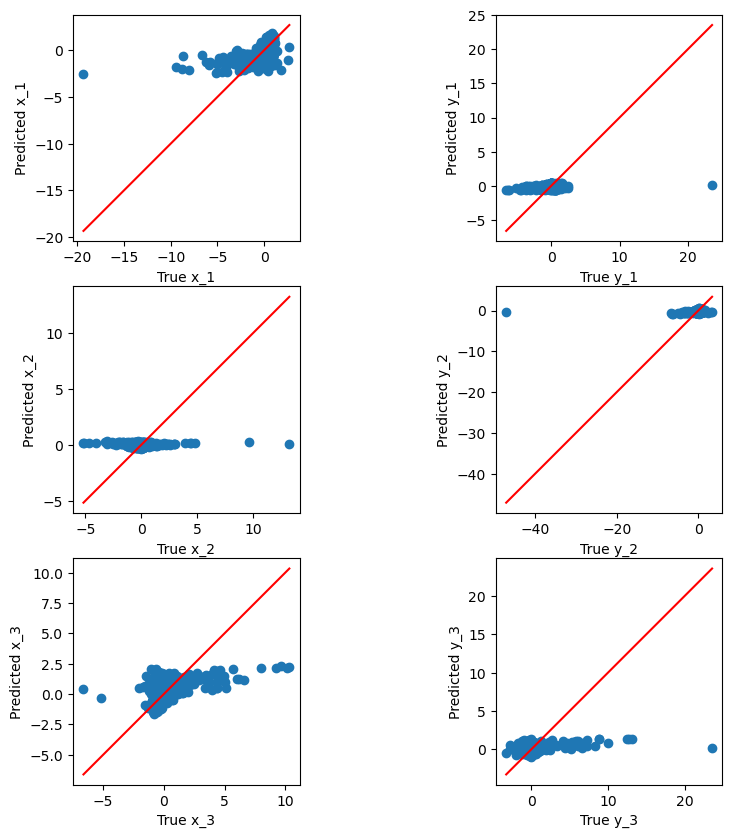

Validation RMSE: 1.3739753683923954


In [22]:
plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

RMSE on the test set

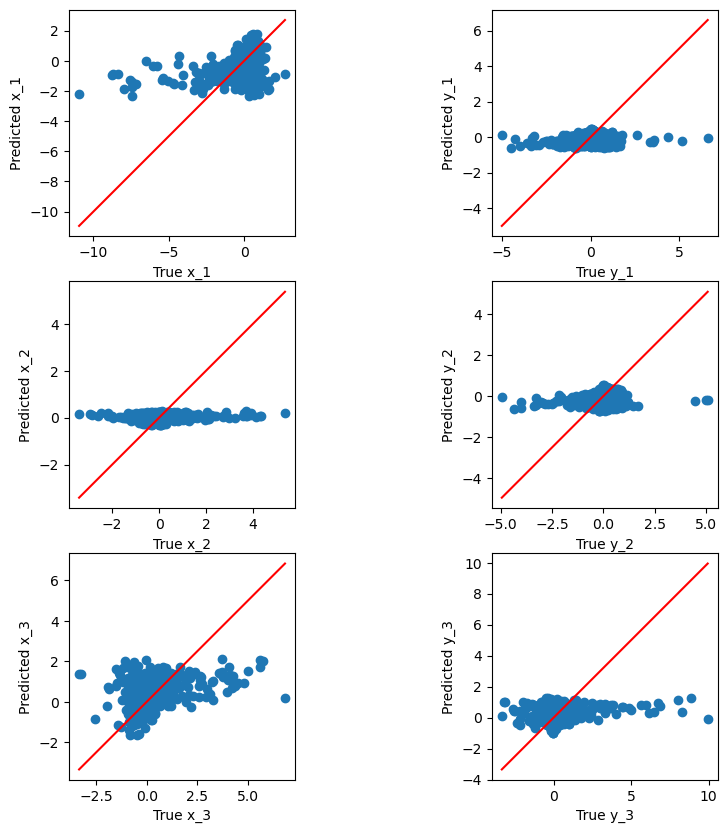

Test RMSE: 1.2949972838306933


In [23]:
y_test_pred = polyreg.predict(X_test_df)
y_test_pred_positions = y_test_pred[:, [0, 1, 4, 5, 8, 9]] 

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

Dataframe containing X_tests' info for submissions. Function to save model output into csv file ready for submission

In [24]:
X_kaggle_df = pd.read_csv('../mlNOVA/X_test.csv')
X_kaggle_df.drop(columns=['Id'], inplace=True)

X_kaggle_df['v_x0_1'] = 0.0
X_kaggle_df['v_y0_1'] = 0.0
X_kaggle_df['v_x0_2'] = 0.0
X_kaggle_df['v_y0_2'] = 0.0
X_kaggle_df['v_x0_3'] = 0.0
X_kaggle_df['v_y0_3'] = 0.0

X_kaggle_df = X_kaggle_df[['t', 'x0_1', 'y0_1', 'v_x0_1', 'v_y0_1', 'x0_2', 'y0_2', 'v_x0_2', 'v_y0_2', 'x0_3', 'y0_3', 'v_x0_3', 'v_y0_3']]

In [25]:
def save_predictions(predictions, path):
    df = pd.DataFrame(predictions, columns=['x_1', 'y_1', 'v_x_1', 'v_y_1', 'x_2', 'y_2', 'v_x_2', 'v_y_2', 'x_3', 'y_3', 'v_x_3', 'v_y_3'])
    
    df_positions = df[['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    
    df_positions['Id'] = df_positions.index
    
    df_positions = df_positions[['Id', 'x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    
    df_positions.to_csv(path, index=False)

Regarding the baseline model for submission of task 1.2

In [26]:
y_baseline_pred = polyreg.predict(X_kaggle_df)

save_predictions(y_baseline_pred, '../submissions/baseline_model.csv')

C:\Users\rasvi\AppData\Local\Temp\ipykernel_2624\3294152544.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_positions['Id'] = df_positions.index


# Task 2: Nonlinear models on the data — the Polynomial model

## Task 2.1 Development

In [38]:
def validate_poly_regression(X_train, y_train, X_val, y_val, regressor=None, degrees=range(1, 9), max_features=None):
    best_rmse = np.inf
    best_model = None
    best_degree = None
    
    X_train_sample, y_train_sample = resample(X_train, y_train, n_samples=int(0.01 * len(X_train)))

    for degree in degrees:
        
        poly = PolynomialFeatures(degree, include_bias=False)
        
        # Default to Linear Regression if no regressor is specified
        if regressor is None:
            polyreg = make_pipeline(StandardScaler(), poly, LinearRegression())
        else:
            polyreg = make_pipeline(StandardScaler(), poly, regressor)
            
        polyreg.fit(X_train_sample, y_train_sample)
        
        n_features = poly.n_output_features_
        
        # Abort if number of features exceeds the limit
        if max_features is not None and n_features > max_features:
            break
            
        
        y_pred = polyreg.predict(X_val)
        
        position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

        y_val_positions = y_val[position_columns].values
        y_pred_positions = y_pred[:, [0, 1, 4, 5, 8, 9]] 
        
        rmse = root_mean_squared_error(y_val_positions, y_pred_positions)
        
        print(f"Degree {degree}: {n_features} features | rmse: {rmse}")
        
        if rmse < best_rmse:
            best_rmse = rmse
            best_model = polyreg
            best_degree = degree
            
    print(f"Best Degree: {best_degree}, RMSE: {best_rmse}")
    
    return best_model, best_degree, best_rmse


In [ ]:
model, degree, rmse = validate_poly_regression(X_train_df, y_train_df, X_dev_df, y_dev_df, degrees=range(1, 6), regressor=RidgeCV())

Degree 1: 13 features | rmse: 1.3235373469063176
Degree 2: 104 features | rmse: 1.2920523909887085
Degree 3: 559 features | rmse: 1.2592187752260882
Degree 4: 2379 features | rmse: 1.2345127620114995


Track degrees and RMSEs over multiple runs

In [77]:
degree_counts = {degree: 0 for degree in range(1,9)}

for run in range(10):
    model, degree, rmse = validate_poly_regression(X_train_df, y_train_df, X_dev_df, y_dev_df, degrees=range(1, 9))
    
    degree_counts[degree] += 1
  
plt.bar(degree_counts.keys(), degree_counts.values())
plt.xlabel('Polynomial Degree')
plt.ylabel('Frequency of Selection')
plt.title('Distribution of Best Polynomial Degree over Multiple Runs')
plt.show()

Degree 1: 13 features | rmse: 1.3210080600678256
Degree 2: 104 features | rmse: 1.2794742797960594
Degree 3: 559 features | rmse: 1.2431897537027714
Degree 4: 2379 features | rmse: 1.2099967490974362
Degree 5: 8567 features | rmse: 1.1767126880020422
Degree 6: 27131 features | rmse: 1.1433674018918265


MemoryError: Unable to allocate 60.1 GiB for an array with shape (104085, 77519) and data type float64

Degree 1: 7 features
Degree 2: 35 features
Degree 3: 119 features
Degree 4: 329 features
Degree 5: 791 features
Degree 6: 1715 features
Degree 7: 3431 features
Degree 8: 6434 features
Best Degree: 8, RMSE: 1.1238656018473543
Degree 1: 7 features
Degree 2: 35 features
Degree 3: 119 features
Degree 4: 329 features
Degree 5: 791 features
Degree 6: 1715 features
Degree 7: 3431 features
Degree 8: 6434 features
Best Degree: 8, RMSE: 1.1319171796961893
Degree 1: 7 features
Degree 2: 35 features
Degree 3: 119 features
Degree 4: 329 features
Degree 5: 791 features
Degree 6: 1715 features
Degree 7: 3431 features
Degree 8: 6434 features
Best Degree: 8, RMSE: 1.1166363729883444
Degree 1: 7 features
Degree 2: 35 features
Degree 3: 119 features
Degree 4: 329 features
Degree 5: 791 features
Degree 6: 1715 features
Degree 7: 3431 features
Degree 8: 6434 features
Best Degree: 8, RMSE: 1.1385424927923513
Degree 1: 7 features
Degree 2: 35 features
Degree 3: 119 features
Degree 4: 329 features
Degree 5: 7

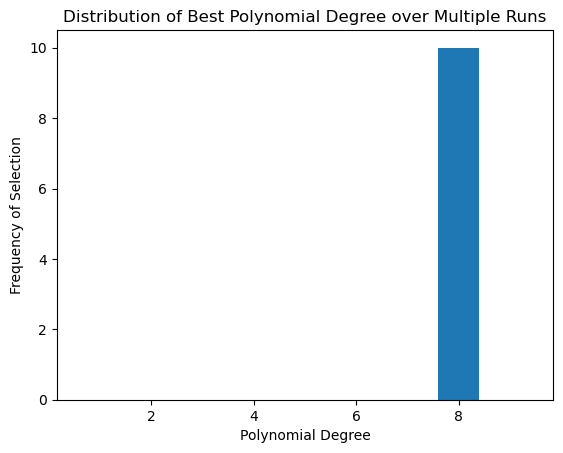

In [124]:
degree_counts = {degree: 0 for degree in range(1,10)}

for run in range(10):
    model, degree, rmse = validate_poly_regression(X_train_df, y_train_df, X_dev_df, y_dev_df, regressor = RidgeCV(), degrees=range(1, 9))
    
    # Track the best degree for this run
    degree_counts[degree] += 1
  
plt.bar(degree_counts.keys(), degree_counts.values())
plt.xlabel('Polynomial Degree')
plt.ylabel('Frequency of Selection')
plt.title('Distribution of Best Polynomial Degree over Multiple Runs')
plt.show()

## Task 2.2 Evaluation

### Evaluate your new nonlinear model against your baseline. Compare RMSE and the y-y hat plots. 

8 was the best performing degree of polynomial in linear regression. But given the size of the training data used to train the model, there is not enough memory to fit it to a 8th degree polynomial regression. The best we could do is degree 7, which as shown by the histogram above, is one of the contenders for best model.

In [111]:
degree=7

polyreg = make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('polynomialfeatures',
                 PolynomialFeatures(degree=7, include_bias=False)),
                ('linearregression', LinearRegression())])

Plot y-y hat in validation set and present RMSE

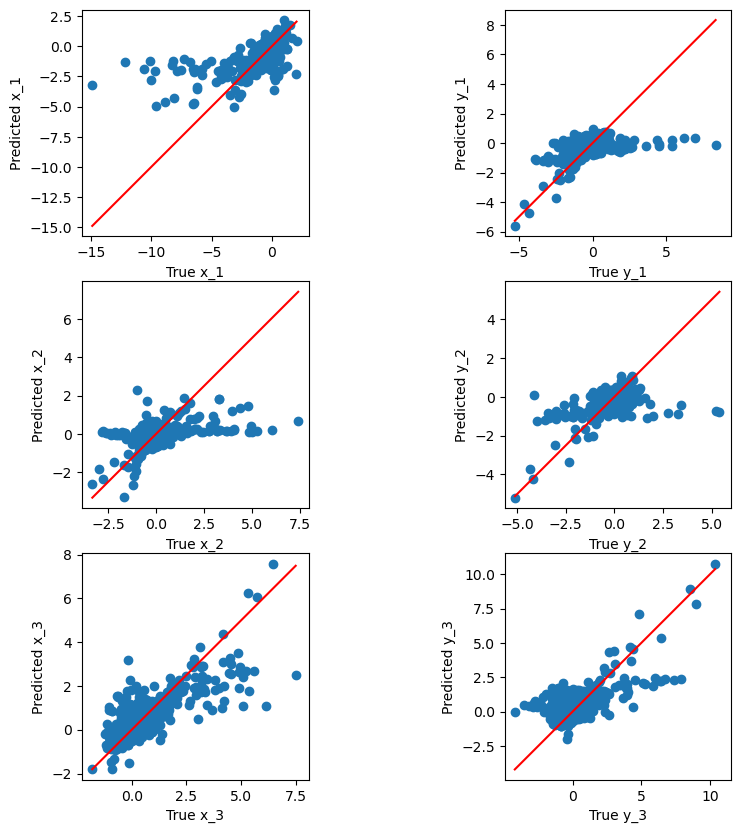

Validation RMSE: 1.1300981269260761


In [112]:
y_dev_pred = polyreg.predict(X_dev_df)

position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev_df[position_columns].values
y_pred_positions = y_dev_pred[:, [0, 1, 4, 5, 8, 9]] 

plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

RMSE in the test set

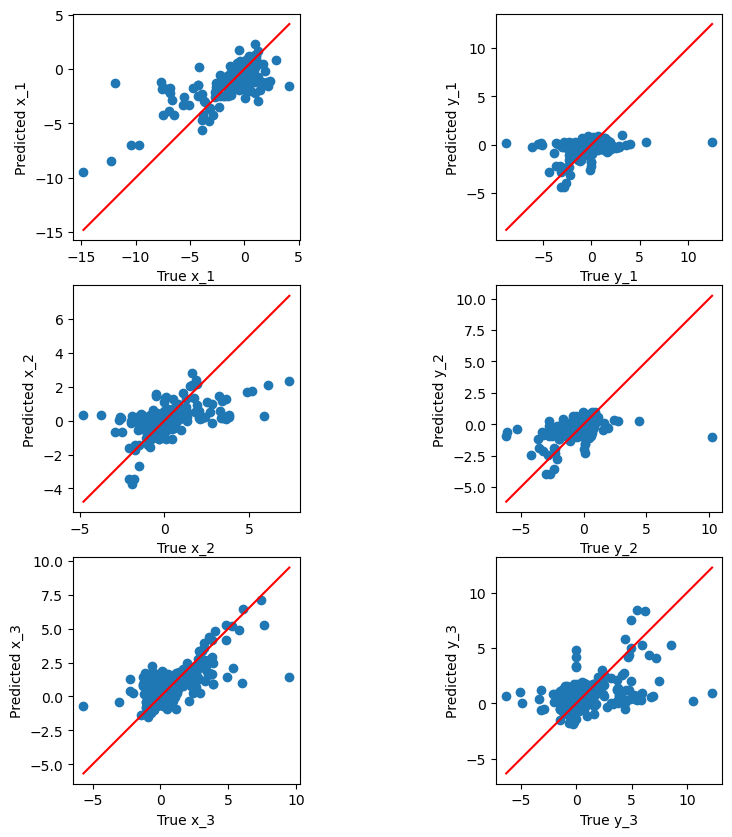

Test RMSE: 1.2615996047843523


In [113]:
y_test_pred = polyreg.predict(X_test_df)
y_test_pred_positions = y_test_pred[:, [0, 1, 4, 5, 8, 9]]
y_test_positions = y_test_df[position_columns].values

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

Regarding the polynomial model for submission of task 2.2

In [114]:
y_polynomial_pred = polyreg.predict(X_kaggle_df)

save_predictions(y_polynomial_pred, '../submissions/polynomial_submission.csv')

Try out RidgeCV and the best degree was 4

In [20]:
degree=4

polyreg=make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      RidgeCV())

# Fit the model
polyreg.fit(X_train_df, y_train_df)

# Predict the targets for the validation set
y_dev_pred = polyreg.predict(X_dev_df)

RMSE in validation set for RidgeCV

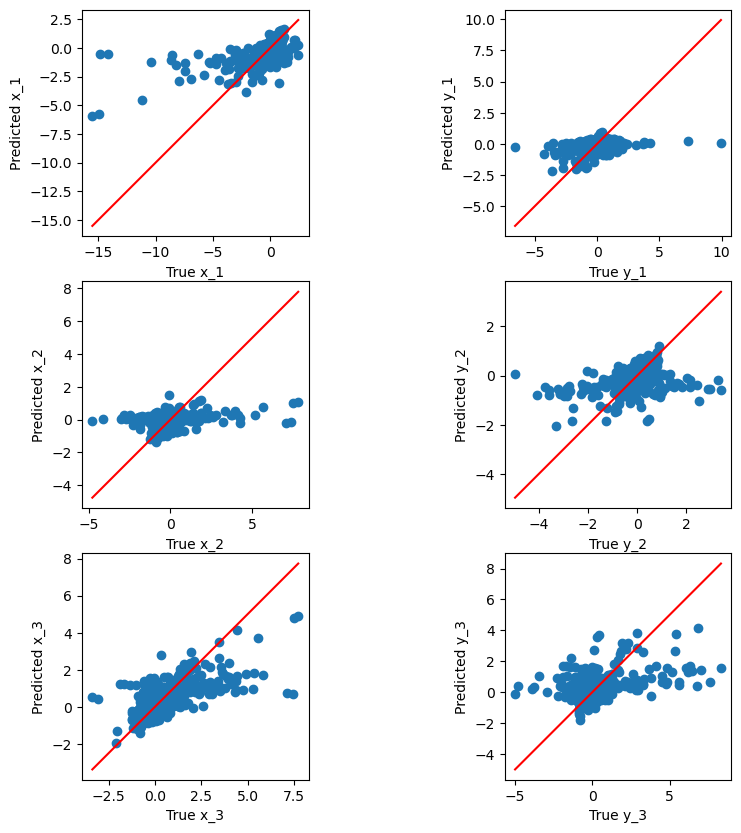

Validation RMSE: 1.2102075819993354


In [21]:
position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev_df[position_columns].values
y_pred_positions = y_dev_pred[:, [0, 1, 4, 5, 8, 9]] 

plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

# Calculate RMSE for the validation set
rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

RMSE in test set for RidgeCV

In [23]:
# Predict the targets for the test set
y_test_pred = polyreg.predict(X_test_df)

y_test_pred_positions = y_test_pred[:, [0, 1, 4, 5, 8, 9]]
y_test_positions = y_test_df[position_columns].values


# Calculate RMSE for the test set
rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

Test RMSE: 1.3428558174085905


# Task 3: Feature Engineering

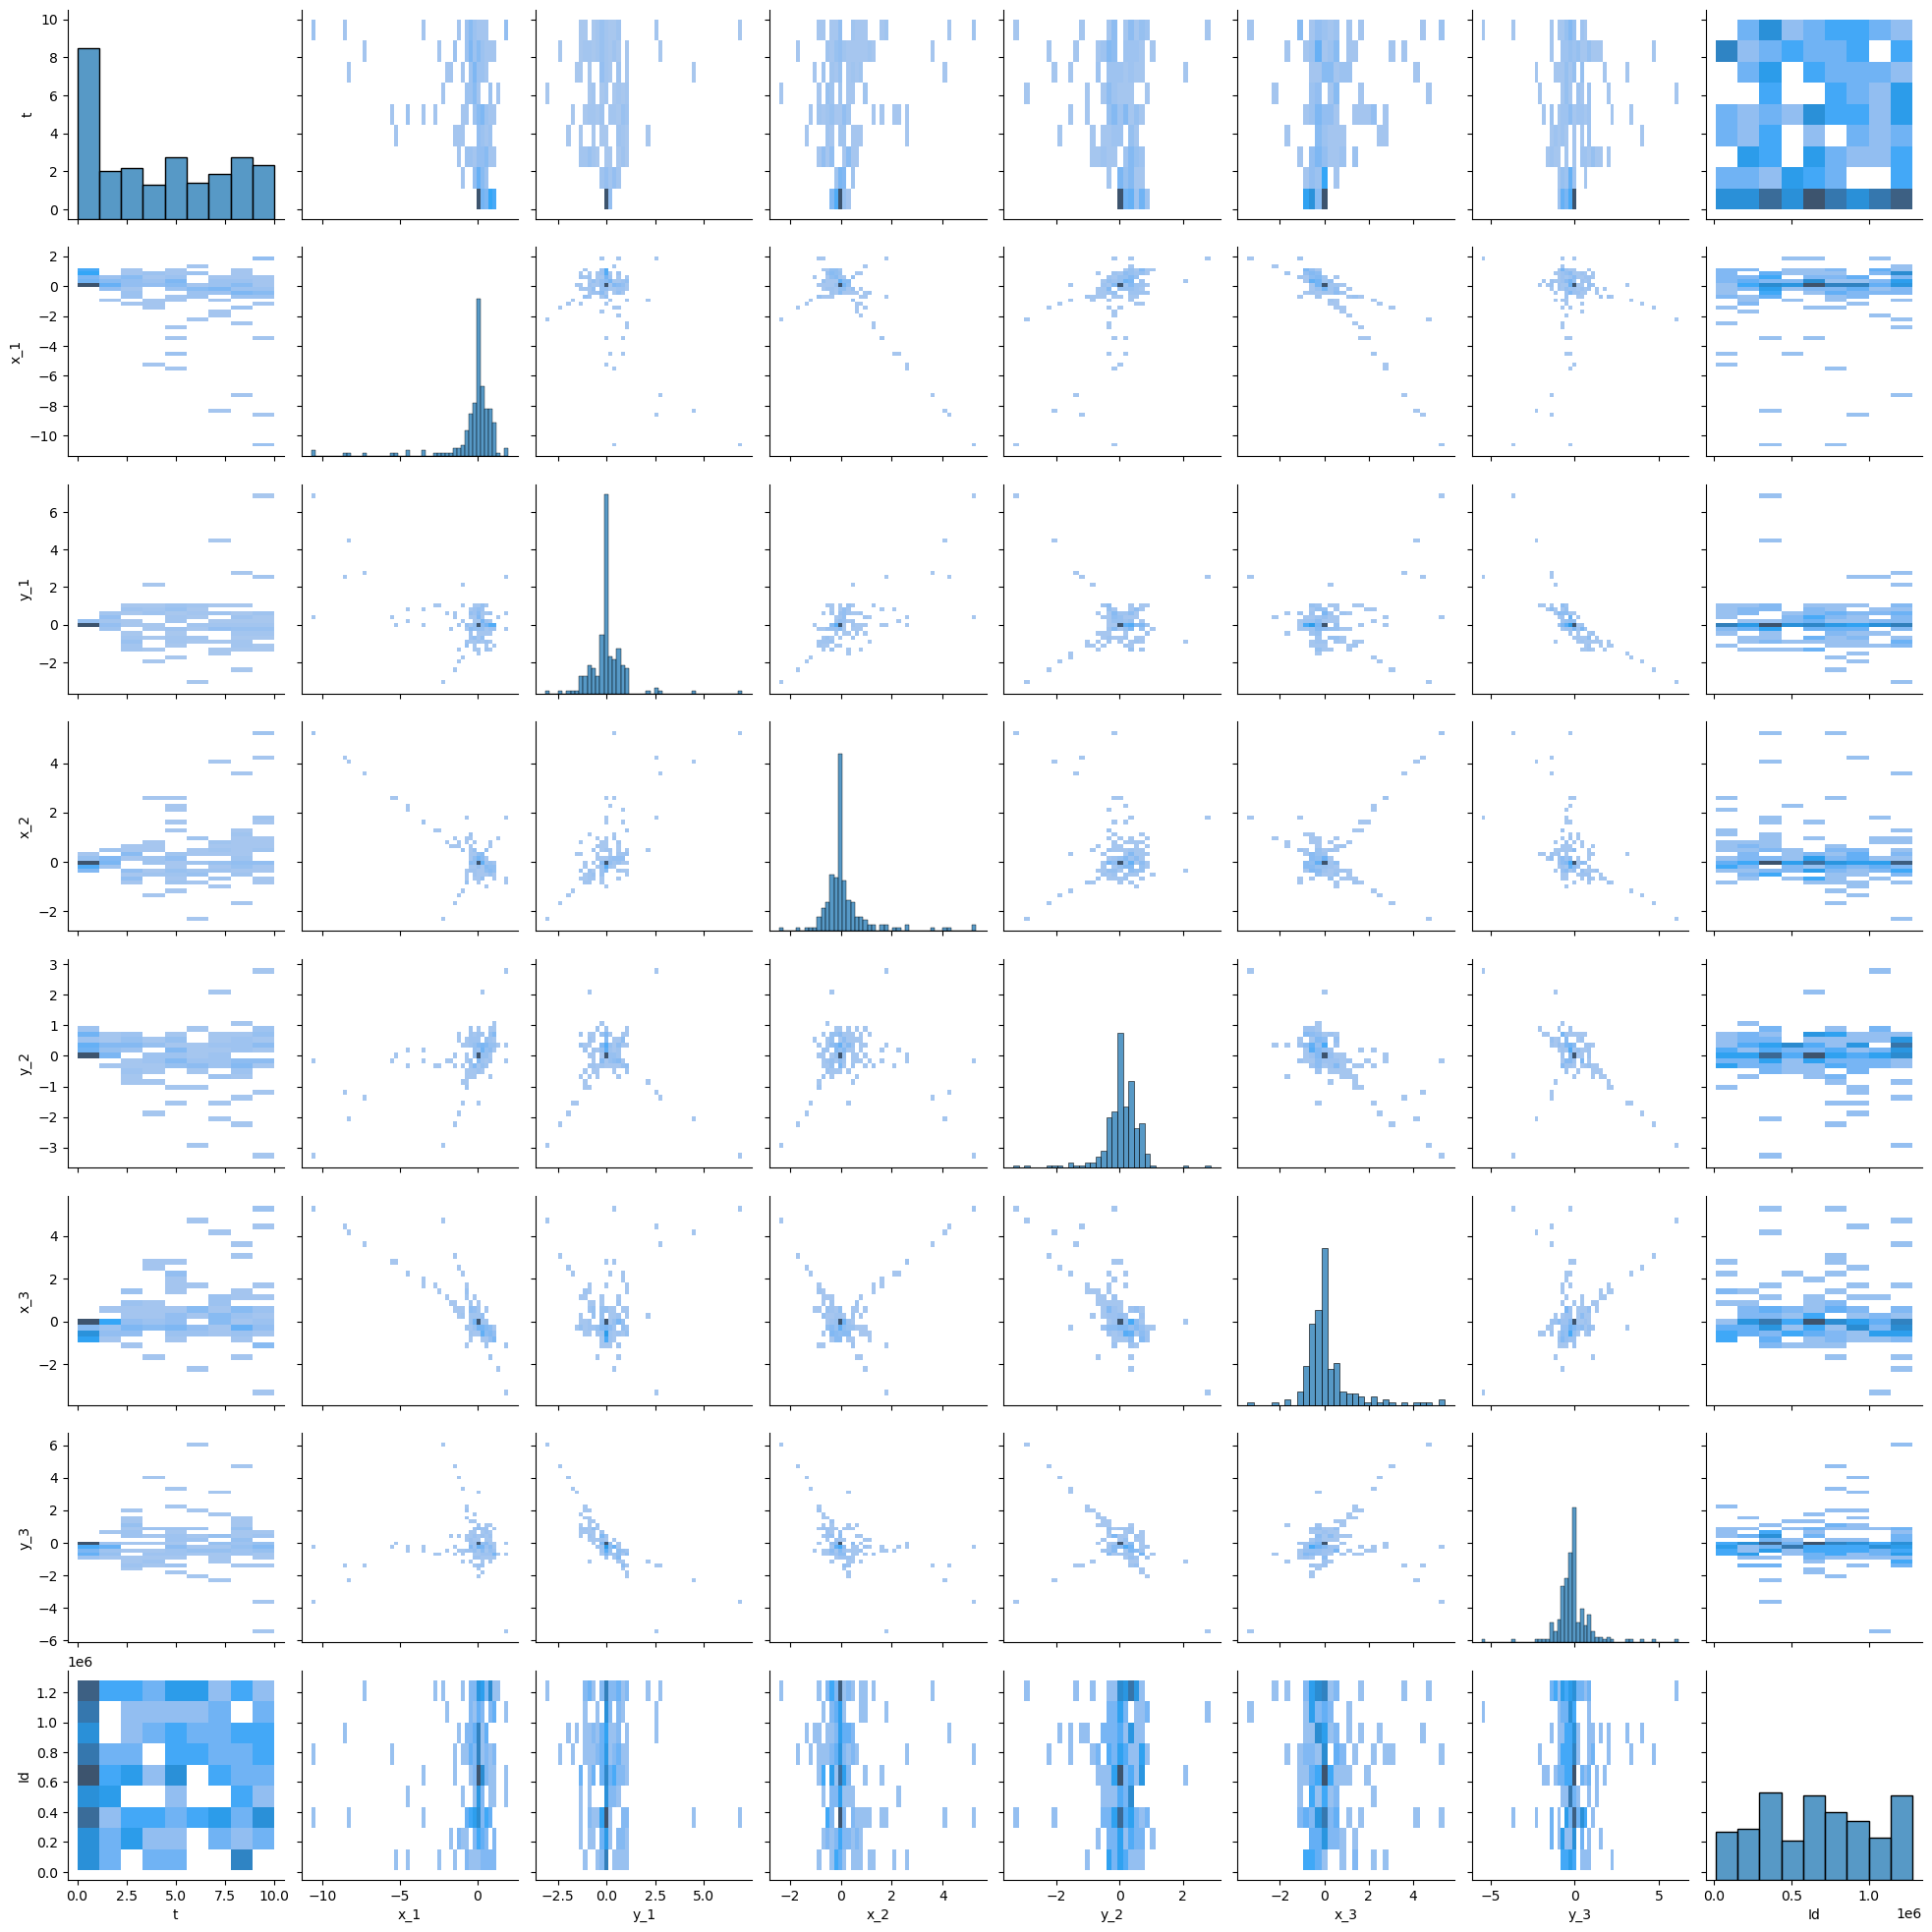

In [6]:
import seaborn as sns
sns.pairplot(df.sample(200), kind="hist")